
<div style="background:linear-gradient(135deg,#3B1C68,#7545A6,#A56CC1);padding:28px;border-radius:16px;text-align:center;">

<p style="color:#FDE68A;font-family:Arial;font-size:12px;letter-spacing:3px;font-weight:bold;">
DEEP LEARNING · CAPSTONE PROJECT
</p>

<h1 style="color:#FFFFFF;font-family:'Trebuchet MS',sans-serif;font-size:32px;margin:12px 0;">
🧠 Brain Tumor Classification
</h1>

<h3 style="color:#F3E8FF;font-family:Arial;font-weight:normal;">
Using MRI Brain Images
</h3>

<p style="color:#E9D5FF;font-family:Arial;font-size:14px;line-height:1.8;">
EDA ✦ CNN ✦ Transfer Learning ✦ Grad-CAM<br>
Medical Evaluation ✦ Image Prediction
</p>

<hr style="width:35%;border:1px solid #FDE68A;">

<p style="color:#FFFFFF;font-family:'Trebuchet MS';font-size:16px;">
Developed by <b style="color:#FDE68A;">Agrim Agarwal</b>
</p>

</div>


<div style="display:flex;flex-wrap:wrap;gap:10px;font-family:Arial;">
  <div style="flex:1;min-width:160px;background:#EAF2FF;border-radius:10px;padding:12px;border-top:5px solid #2F6FDE;"><b>📦 Dataset</b><br>Brain Tumor MRI Dataset (Kaggle)</div>
  <div style="flex:1;min-width:160px;background:#E8F8F5;border-radius:10px;padding:12px;border-top:5px solid #0E9F8E;"><b>🏷️ Classes</b><br>glioma · meningioma · pituitary · no tumor</div>
  <div style="flex:1;min-width:160px;background:#FFF4E5;border-radius:10px;padding:12px;border-top:5px solid #F5900F;"><b>🧠 Models</b><br>Custom CNN + EfficientNetB0</div>
  <div style="flex:1;min-width:160px;background:#F3EDFF;border-radius:10px;padding:12px;border-top:5px solid #6C3FC5;"><b>🛠️ Tools</b><br>TensorFlow · Keras · Kaggle GPU</div>
</div>

<div style="background:#FFF1F1;border-left:6px solid #D64545;border-radius:8px;padding:12px 18px;font-family:Arial;font-size:14.5px;">
⚕️ <b>Disclaimer:</b> This is an <b>educational project</b>. The model is NOT a medical device and must never be used to diagnose real patients.
In real hospitals, AI only <i>assists</i> radiologists — the doctor makes the final decision.
</div>

<div style="background:#F7F9FC;border-radius:10px;padding:16px 22px;font-family:Arial;font-size:15px;">
<h3 style="font-family:Georgia;color:#0C244A;margin-top:0;">🗺️ Project Roadmap</h3>
<ol style="line-height:1.9;">
<li>Medical problem &amp; Kaggle setup</li>
<li>Import libraries &amp; check GPU</li>
<li>Locate the dataset &amp; set configuration</li>
<li>Exploratory Data Analysis on MRI scans</li>
<li>Build the data pipeline (<code>tf.data</code>)</li>
<li>Data augmentation (MRI-safe)</li>
<li>Model 1 — CNN from scratch (baseline)</li>
<li>Model 2 — Transfer learning with EfficientNetB0 (+ fine-tuning)</li>
<li>Compare models &amp; evaluate on the unseen test set</li>
<li>Medical evaluation — Tumor vs No-Tumor: sensitivity, specificity &amp; missed tumors</li>
<li>Error analysis</li>
<li>Explainability with Grad-CAM — is the model looking at the tumor?</li>
<li>Save the model &amp; predict on new scans</li>
<li>Conclusion, summary &amp; student tasks</li>
</ol>
</div>

<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 1</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🎯 Medical Problem & Kaggle Setup</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Why are we building this, and how do we prepare the Kaggle notebook?</p>
</div>

<div style="border:2px solid #2F6FDE;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2F6FDE;font-family:Georgia;margin:0 0 8px 0;">🏥 The Problem</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">A hospital's radiology department reads <b>hundreds of brain MRI scans</b> every day. Doctors are overloaded, and a
     delayed diagnosis can be dangerous.<br><br>
     Goal ➜ build a <b>Deep Learning assistant</b> that looks at an MRI scan and predicts whether it shows
     <b>glioma, meningioma, pituitary tumor, or no tumor</b> — so urgent cases reach the doctor first (<b>triage</b>).<br><br>
     🧩 <b>ML type:</b> Supervised · <b>Multi-class image classification</b> (4 classes)<br>
     📏 <b>Success metrics:</b> Test accuracy (target <b>&gt; 95%</b>) <b>and</b> very few tumors predicted as “no tumor” (missed tumors)</div>
</div>

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">🩻 The 4 classes in simple words</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><table style="font-size:14px;">
     <tr><th style="text-align:left;">Class</th><th style="text-align:left;">What it is</th><th style="text-align:left;">Where it usually appears</th></tr>
     <tr><td><b>glioma</b></td><td>Tumor growing from the brain's glial (support) cells — often aggressive</td><td>Inside the brain tissue</td></tr>
     <tr><td><b>meningioma</b></td><td>Tumor of the meninges (the brain's protective covering) — usually slow-growing</td><td>Near the skull / brain surface</td></tr>
     <tr><td><b>pituitary</b></td><td>Tumor of the pituitary gland (the hormone “control centre”)</td><td>Base of the brain, centre</td></tr>
     <tr><td><b>notumor</b></td><td>Healthy scan</td><td>—</td></tr>
     </table><br>
     💡 Notice: tumor <b>location</b> is a strong clue — a good model should learn to look at the right region!</div>
</div>

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">📦 About the Dataset</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><b>Brain Tumor MRI Dataset</b> — <a href="https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset" target="_blank">kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset</a><br><br>
     <table style="font-size:14px;">
     <tr><th style="text-align:left;">Folder</th><th style="text-align:left;">What's inside</th><th style="text-align:left;">We use it for</th></tr>
     <tr><td><code>Training/</code></td><td>~5,700 labelled MRI images (one sub-folder per class)</td><td>Training + Validation</td></tr>
     <tr><td><code>Testing/</code></td><td>~1,300 labelled MRI images</td><td>Final test (unseen)</td></tr>
     </table><br>
     Images are <b>different sizes</b> (mostly around 512 × 512) and are greyscale scans saved as JPG.</div>
</div>

<div style="border:2px solid #F5900F;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#F5900F;font-family:Georgia;margin:0 0 8px 0;">⚙️ Kaggle Notebook Setup (do this first!)</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><ol style="margin:0;">
     <li>Create a new notebook on Kaggle (<b>Code ➜ New Notebook</b>) and upload this <code>.ipynb</code> via <b>File ➜ Import Notebook</b>.</li>
     <li>Right panel ➜ <b>+ Add Input</b> ➜ search <b>“brain tumor mri dataset masoud nickparvar”</b> ➜ click <b>Add</b>.</li>
     <li>Settings ➜ <b>Accelerator ➜ GPU T4 x2</b> (or P100). 🚀</li>
     <li>Settings ➜ <b>Internet ➜ On</b> (needed to download the pretrained EfficientNet weights).</li>
     </ol></div>
</div>

<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 2</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">📚 Import Libraries & Check GPU</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Our toolbox for this project</p>
</div>

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">🧰 What each library does</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><b>numpy / pandas</b> ➜ numbers &amp; tables · <b>matplotlib / seaborn</b> ➜ charts · <b>PIL</b> ➜ open image files<br>
     <b>tensorflow / keras</b> ➜ build &amp; train neural networks · <b>sklearn</b> ➜ evaluation metrics</div>
</div>

In [1]:
import os, random, json, hashlib, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

print("TensorFlow version :", tf.__version__)
print("GPU available      :", tf.config.list_physical_devices("GPU"))

TensorFlow version : 2.20.0
GPU available      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


<div style="border:2px solid #6C3FC5;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#6C3FC5;font-family:Georgia;margin:0 0 8px 0;">🎲 Reproducibility — fixing the seed</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Weights start random and data is shuffled randomly. Fixing a seed is like shuffling a deck of cards the
     <i>same way every time</i> — so everyone in class gets (almost) the same results.</div>
</div>

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 3</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">📂 Locate the Dataset & Set Configuration</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Find the folders automatically and keep all settings in one place</p>
</div>

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">💡 Why search for the path?</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Kaggle's input path can change (and some versions of this dataset have an extra parent folder).
     Instead of hard-coding it, we <b>walk through</b> <code>/kaggle/input</code> and find the folder that contains the class sub-folders.</div>
</div>

In [4]:
INPUT_ROOT = "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"

def find_split_dir(prefix, a_class="glioma"):
    """Return the folder whose name starts with `prefix` (e.g. 'train') and contains the class sub-folders."""
    for root, dirs, files in os.walk(INPUT_ROOT):
        name = os.path.basename(root).lower()
        if name.startswith(prefix) and a_class in [d.lower() for d in dirs]:
            return root
    return None

TRAIN_DIR = find_split_dir("training")
TEST_DIR  = find_split_dir("testing")

print("Train folder :", TRAIN_DIR)
print("Test folder  :", TEST_DIR)
assert TRAIN_DIR and TEST_DIR, "Dataset not found! Did you click '+ Add Input' and add the Brain Tumor MRI dataset?"

Train folder : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Test folder  : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing


In [5]:
# ---------- All project settings in ONE place ----------
IMG_SIZE    = (224, 224)   # MRI details are small ➜ use a larger size than 150x150
BATCH_SIZE  = 32
VAL_SPLIT   = 0.20         # 20% of training images kept aside for validation
EPOCHS_CNN  = 30           # max epochs for the scratch CNN (EarlyStopping may stop sooner)
EPOCHS_HEAD = 10           # transfer learning – stage A (train new head)
EPOCHS_FT   = 15           # transfer learning – stage B (fine-tune)
OUTPUT_DIR  = "/kaggle/working"

CLASS_NAMES = sorted(os.listdir(TRAIN_DIR))
NUM_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES, "| Total:", NUM_CLASSES)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary'] | Total: 4


<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 4</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🔍 Exploratory Data Analysis (EDA)</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Get to know the scans before training — like a radiology intern 🩺</p>
</div>

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">❓ Questions EDA answers</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><ul style="margin:0;"><li>How many scans per class? Is the data <b>balanced</b>?</li>
     <li>What do the 4 classes look like?</li>
     <li>Are the images the same <b>size</b> and <b>colour mode</b>?</li>
     <li>Are there <b>duplicate</b> images — especially between train and test? (data leakage!)</li></ul></div>
</div>

In [6]:
def count_images(folder):
    return {c: len(os.listdir(os.path.join(folder, c))) for c in CLASS_NAMES}

counts_df = pd.DataFrame({"train": count_images(TRAIN_DIR), "test": count_images(TEST_DIR)})
counts_df["train_%"] = (counts_df["train"] / counts_df["train"].sum() * 100).round(1)
counts_df.loc["TOTAL"] = counts_df.sum()
counts_df

,train,test,train_%
glioma,1400.0,400.0,25.0
meningioma,1400.0,400.0,25.0
notumor,1400.0,400.0,25.0
pituitary,1400.0,400.0,25.0
TOTAL,5600.0,1600.0,100.0


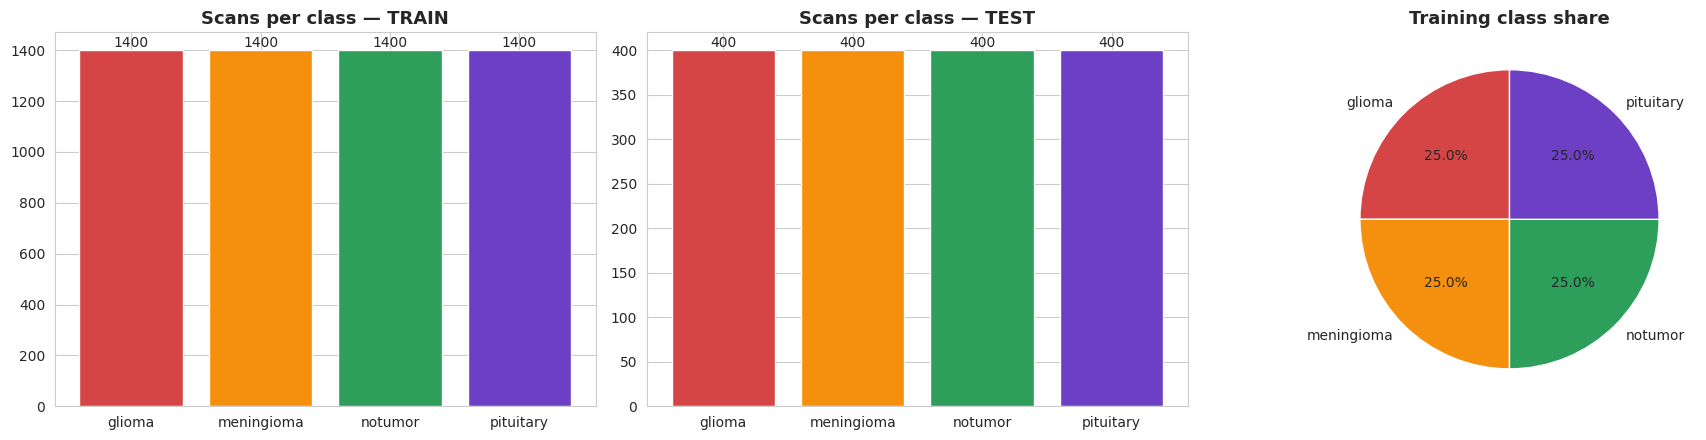

In [7]:
plot_df = counts_df.drop("TOTAL")
colors = ["#D64545", "#F5900F", "#2E9E5B", "#6C3FC5"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, split in zip(axes[:2], ["train", "test"]):
    bars = ax.bar(plot_df.index, plot_df[split], color=colors)
    ax.bar_label(bars)
    ax.set_title(f"Scans per class — {split.upper()}", fontsize=13, fontweight="bold")
axes[2].pie(plot_df["train"], labels=plot_df.index, autopct="%1.1f%%", colors=colors, startangle=90)
axes[2].set_title("Training class share", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 Observation</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">All 4 classes have roughly <b>1,300–1,600</b> training scans ➜ <b>fairly balanced</b>, with <b>notumor</b> slightly larger.
     We'll still compute <b>class weights</b> as a safety net, so the model doesn't favour the bigger class.</div>
</div>

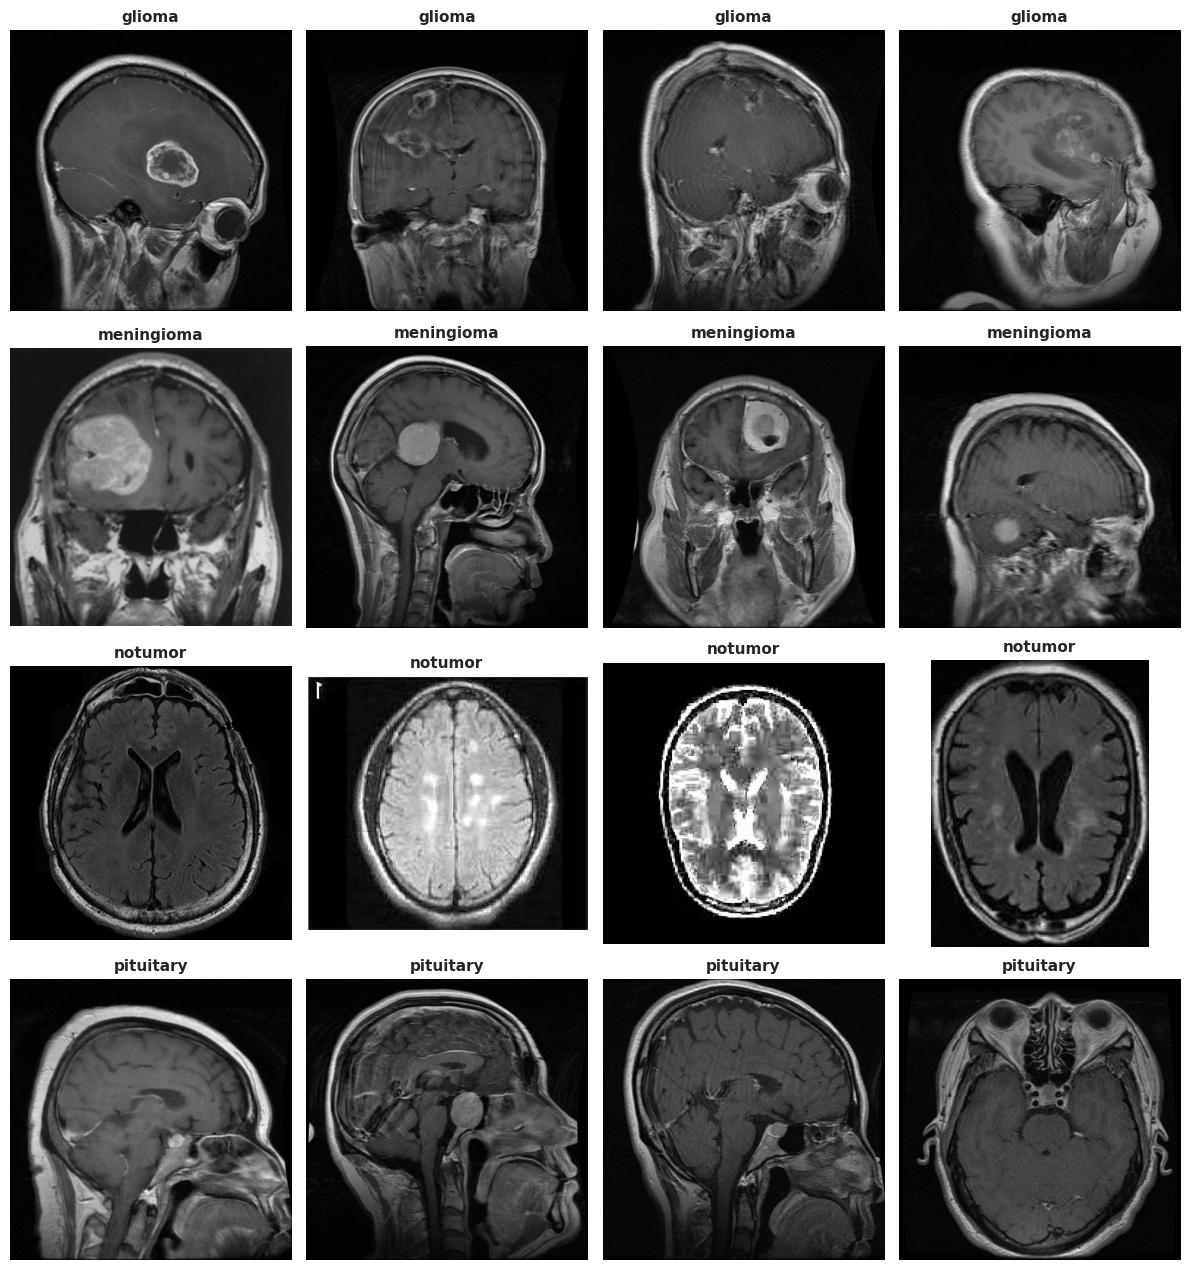

In [8]:
# Show 4 random scans from each class
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(12, 3.2 * NUM_CLASSES))
for i, cls in enumerate(CLASS_NAMES):
    files = random.sample(os.listdir(os.path.join(TRAIN_DIR, cls)), 4)
    for j, f in enumerate(files):
        axes[i, j].imshow(Image.open(os.path.join(TRAIN_DIR, cls, f)).convert("RGB"))
        axes[i, j].set_title(cls, fontsize=11, fontweight="bold")
        axes[i, j].axis("off")
plt.tight_layout(); plt.show()

<div style="border:2px solid #6C3FC5;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#6C3FC5;font-family:Georgia;margin:0 0 8px 0;">👀 Think like a radiologist</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Scans come from <b>different angles</b> (top view, side view, front view) and different machines — so brightness and
     contrast vary. <b>Glioma vs meningioma</b> can look similar, while <b>pituitary</b> tumors sit near the centre-bottom.
     Expect most confusion between glioma and meningioma.</div>
</div>

Colour modes : Counter({'RGB': 337, 'L': 263})
Distinct sizes in sample: 87
Most common (width, height):
  (512, 512): 429
  (225, 225): 29
  (630, 630): 7
  (228, 221): 5
  (201, 251): 4


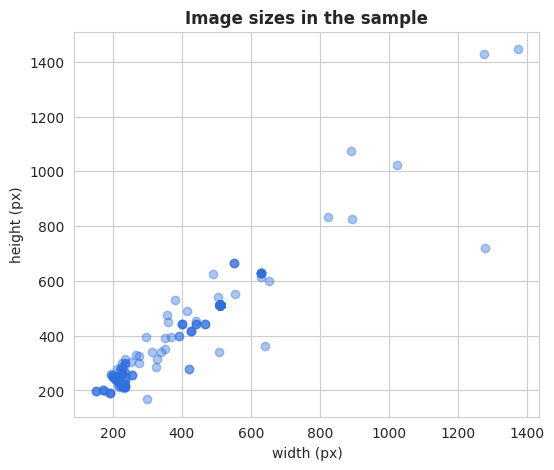

In [9]:
# Check image sizes and colour modes on a random sample
sizes, modes = [], []
for cls in CLASS_NAMES:
    folder = os.path.join(TRAIN_DIR, cls)
    for f in random.sample(os.listdir(folder), 150):
        with Image.open(os.path.join(folder, f)) as im:
            sizes.append(im.size); modes.append(im.mode)

print("Colour modes :", Counter(modes))
print("Distinct sizes in sample:", len(set(sizes)))
print("Most common (width, height):")
for s, n in Counter(sizes).most_common(5):
    print(f"  {s}: {n}")

w, h = zip(*sizes)
plt.figure(figsize=(6, 5))
plt.scatter(w, h, alpha=0.4, color="#2F6FDE")
plt.xlabel("width (px)"); plt.ylabel("height (px)")
plt.title("Image sizes in the sample", fontweight="bold"); plt.show()

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 Observation</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Sizes vary a lot (from ~200 px up to 1,000+ px), and some files are greyscale (<b>L</b>) while others are <b>RGB</b>.
     The data loader will <b>resize everything to 224 × 224</b> and convert to <b>3 channels</b> — exactly what pretrained models expect.</div>
</div>

<div style="border:2px solid #D64545;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#D64545;font-family:Georgia;margin:0 0 8px 0;">🚨 Data leakage check — duplicate scans</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Medical datasets are often built by merging several public sources, so the <b>same scan can appear twice</b> —
     sometimes once in train and once in test. If that happens, the model has “seen the exam paper” and the test score is
     <b>too optimistic</b>. We detect exact duplicates using an <b>MD5 hash</b> (a fingerprint of the file).</div>
</div>

In [10]:
def file_hashes(folder):
    rows = []
    for cls in CLASS_NAMES:
        for f in os.listdir(os.path.join(folder, cls)):
            path = os.path.join(folder, cls, f)
            with open(path, "rb") as fh:
                rows.append((hashlib.md5(fh.read()).hexdigest(), cls, path))
    return pd.DataFrame(rows, columns=["hash", "label", "path"])

train_hash = file_hashes(TRAIN_DIR)
test_hash  = file_hashes(TEST_DIR)

dup_within_train = train_hash.duplicated("hash").sum()
leak = set(train_hash["hash"]) & set(test_hash["hash"])
conflicting = train_hash.groupby("hash")["label"].nunique().gt(1).sum()

print(f"Duplicate files inside TRAIN        : {dup_within_train}")
print(f"Same file in BOTH train and test    : {len(leak)}")
print(f"Duplicates with DIFFERENT labels    : {conflicting}")

Duplicate files inside TRAIN        : 171
Same file in BOTH train and test    : 0
Duplicates with DIFFERENT labels    : 0


<div style="border:2px solid #F5900F;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#F5900F;font-family:Georgia;margin:0 0 8px 0;">📝 What do we do with duplicates?</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">For this capstone we <b>report</b> them and keep the official split, so results are comparable with other Kaggle notebooks.
     But be honest in your final report: <i>“X test images also appear in training, so the real-world accuracy may be slightly lower.”</i><br>
     🎯 <b>Student task</b> (at the end): remove the leaked images and re-measure test accuracy.</div>
</div>

<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 5</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🚰 Build the Data Pipeline</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Load scans straight from folders with tf.data — fast and memory friendly</p>
</div>

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">🍽️ Analogy: the restaurant kitchen</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Instead of cooking all 5,700 dishes at once, the kitchen prepares <b>one plate of 32 (a batch)</b> while the waiter
     serves the previous one — that's <code>prefetch</code>.<br><br>
     <b>Split plan:</b> Training ➜ 80% <b>train</b> + 20% <b>validation</b> · Testing ➜ <b>test</b> (touched only at the end!)</div>
</div>

In [12]:
train_raw, val_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=VAL_SPLIT,
    subset="both",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",       # greyscale scans are converted to 3 channels
)

test_raw = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    color_mode="rgb",
    shuffle=False,          # keep order fixed so predictions line up with labels
)

CLASS_NAMES = train_raw.class_names
TEST_PATHS  = test_raw.file_paths
NOTUMOR_IDX = CLASS_NAMES.index("notumor")
print("Class index mapping:", dict(enumerate(CLASS_NAMES)))

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Class index mapping: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}


In [13]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds   = val_raw.cache().prefetch(AUTOTUNE)
test_ds  = test_raw.cache().prefetch(AUTOTUNE)

for images, labels in train_ds.take(1):
    print("Batch of images :", images.shape)   # (32, 224, 224, 3)
    print("Batch of labels :", labels.shape)
    print("Pixel range     :", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Batch of images : (32, 224, 224, 3)
Batch of labels : (32,)
Pixel range     : 0.0 to 255.0


In [14]:
# Class weights: give slightly more importance to smaller classes
train_labels = np.concatenate([y.numpy() for _, y in train_raw])
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_labels)
CLASS_WEIGHTS = dict(enumerate(weights))
pd.DataFrame({"class": CLASS_NAMES, "weight": weights.round(3)})

,class,weight
0,glioma,0.982
1,meningioma,0.996
2,notumor,1.018
3,pituitary,1.004


<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 Note on pixel values</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Pixels are still <b>0–255</b>. The scratch CNN rescales inside the model with <code>Rescaling(1/255)</code>;
     EfficientNet has its own preprocessing built in. Preprocessing inside the model ➜ the saved model works on raw scans directly ✅</div>
</div>

<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 6</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🔄 Data Augmentation (MRI-safe)</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Create realistic variations of scans to fight overfitting</p>
</div>

<div style="border:2px solid #F5900F;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#F5900F;font-family:Georgia;margin:0 0 8px 0;">🩻 Which augmentations make sense for MRI?</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">✅ <b>Horizontal flip</b> — the brain is roughly left-right symmetric; a tumor can be on either side.<br>
     ✅ <b>Small rotation &amp; zoom</b> — patients' heads are never perfectly aligned in the scanner.<br>
     ✅ <b>Small contrast change</b> — different MRI machines produce different brightness.<br>
     ❌ <b>Vertical flip / big rotations</b> — an upside-down brain never appears in real scans; it would confuse the model.<br><br>
     ⚠️ Augmentation runs <b>only during training</b> — Keras switches it off for validation, testing and prediction.</div>
</div>

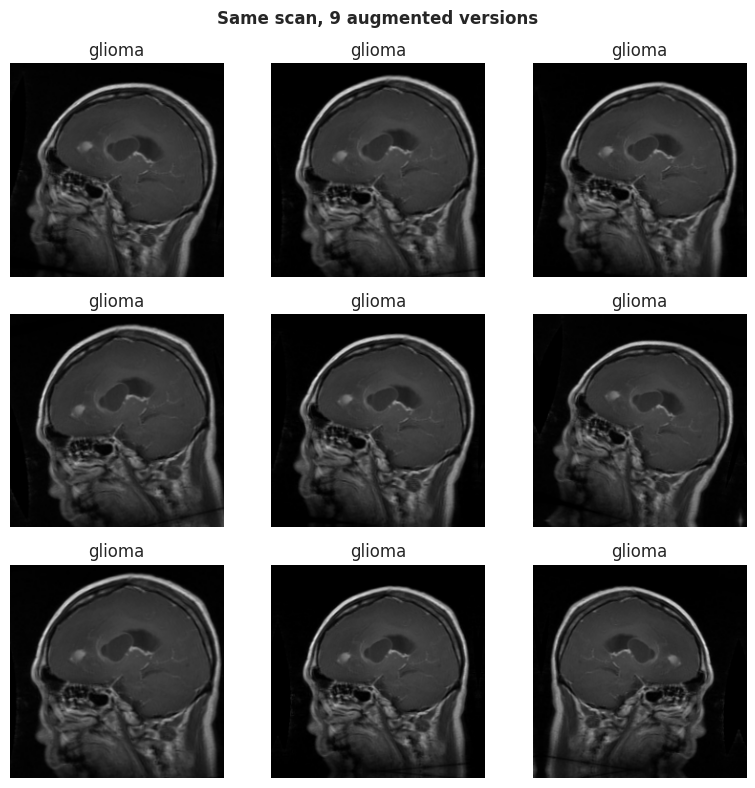

In [15]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),      # ±18 degrees
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

for images, labels in train_raw.take(1):
    sample = images[0]
    plt.figure(figsize=(8, 8))
    for i in range(9):
        aug = data_augmentation(tf.expand_dims(sample, 0), training=True)
        plt.subplot(3, 3, i + 1)
        plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
        plt.title(CLASS_NAMES[labels[0]]); plt.axis("off")
    plt.suptitle("Same scan, 9 augmented versions", fontweight="bold")
    plt.tight_layout(); plt.show()

<div style="background:#2F6FDE;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 7</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🏗️ Model 1 — CNN from Scratch (Baseline)</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Our own convolutional network, trained from zero</p>
</div>

<div style="border:2px solid #2F6FDE;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2F6FDE;font-family:Georgia;margin:0 0 8px 0;">🧱 Architecture idea</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><b>Conv ➜ BatchNorm ➜ ReLU ➜ MaxPool</b> blocks with growing filters (32 ➜ 64 ➜ 128 ➜ 256).<br>
     Early layers detect <b>edges &amp; brightness changes</b>, deeper layers detect <b>shapes &amp; masses</b> (a bright round lump = possible tumor).<br>
     <b>GlobalAveragePooling</b> ➜ <b>Dropout</b> ➜ <b>Dense(4, softmax)</b> gives one probability per class.</div>
</div>

In [16]:
def build_baseline_cnn():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn")

baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,268 (1.61 MB)

 Trainable params: 422,308 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

<div style="border:2px solid #6C3FC5;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#6C3FC5;font-family:Georgia;margin:0 0 8px 0;">🎛️ Compile + Callbacks (our training assistants)</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><b>Loss:</b> <code>sparse_categorical_crossentropy</code> (labels are integers 0–3) · <b>Optimizer:</b> Adam<br>
     🛑 <b>EarlyStopping</b> — stops when validation loss stops improving, restores the best weights<br>
     🐢 <b>ReduceLROnPlateau</b> — halves the learning rate when stuck<br>
     💾 <b>ModelCheckpoint</b> — saves the best model to disk automatically<br>
     ⚖️ <b>class_weight</b> — the class weights we computed in Step 5</div>
</div>

In [17]:
def get_callbacks(filename, patience=6):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
        keras.callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, filename), monitor="val_accuracy",
                                        save_best_only=True, verbose=0),
    ]

baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_cnn = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    class_weight=CLASS_WEIGHTS,
    callbacks=get_callbacks("baseline_cnn.keras"),
)

Epoch 1/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 133ms/step - accuracy: 0.6252 - loss: 0.9103 - val_accuracy: 0.2438 - val_loss: 3.5768 - learning_rate: 0.0010
Epoch 2/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.7083 - loss: 0.7426 - val_accuracy: 0.3830 - val_loss: 2.2882 - learning_rate: 0.0010
Epoch 3/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 132ms/step - accuracy: 0.7308 - loss: 0.6644 - val_accuracy: 0.4643 - val_loss: 1.5043 - learning_rate: 0.0010
Epoch 4/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.7487 - loss: 0.6460 - val_accuracy: 0.5464 - val_loss: 1.7152 - learning_rate: 0.0010
Epoch 5/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.7772 - loss: 0.5754 - val_accuracy: 0.7786 - val_loss: 0.5142 - learning_rate: 0.0010
Epoch 6/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.7768 - loss: 0.5612 - val_accuracy: 0.8277 - val_loss: 0.5198 - learning_rate: 0.0010
Epoch 7/30
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.79

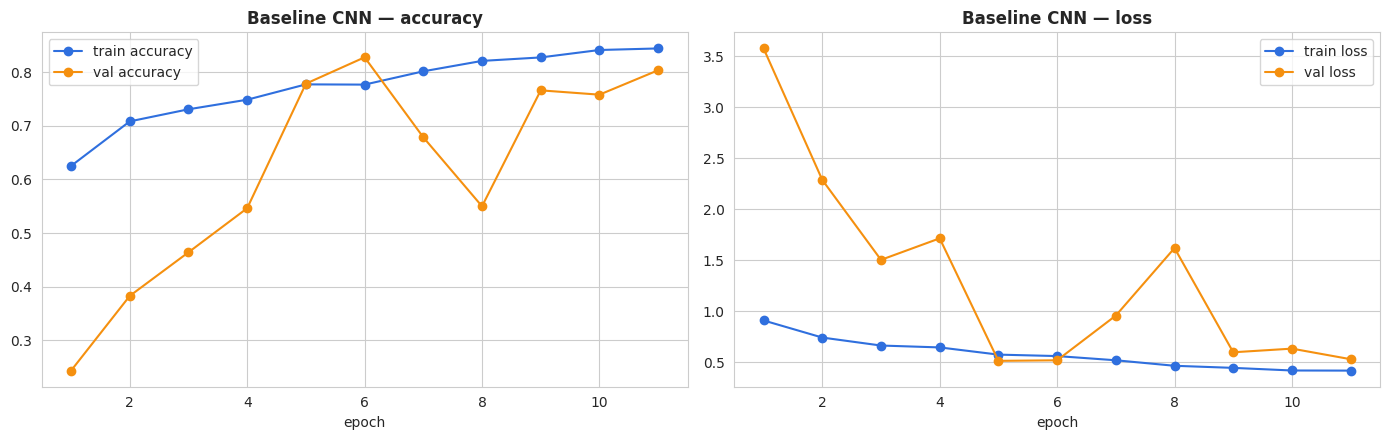

Baseline CNN  ➜  Validation accuracy: 0.7786


In [18]:
def plot_history(histories, title, split_at=None):
    """Plot accuracy & loss curves. `histories` = list of History objects (joined end to end)."""
    hist = {}
    for h in histories:
        for k, v in h.history.items():
            hist.setdefault(k, []).extend(v)
    epochs = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, hist[metric], "o-", label=f"train {metric}", color="#2F6FDE")
        ax.plot(epochs, hist[f"val_{metric}"], "o-", label=f"val {metric}", color="#F5900F")
        if split_at:
            ax.axvline(split_at + 0.5, color="gray", linestyle="--", label="fine-tuning starts")
        ax.set_title(f"{title} — {metric}", fontweight="bold"); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.show()

plot_history([history_cnn], "Baseline CNN")

cnn_val_loss, cnn_val_acc = baseline_model.evaluate(val_ds, verbose=0)
print(f"Baseline CNN  ➜  Validation accuracy: {cnn_val_acc:.4f}")

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 How to read the curves</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">✅ <b>Train &amp; val close together</b> ➜ good fit · ⚠️ <b>Train rises, val flattens/drops</b> ➜ overfitting.<br>
     Validation curves can be <b>bumpy</b> in early epochs because of BatchNorm — that's normal.
     A scratch CNN usually reaches around <b>85–93%</b> here. Can a pretrained model do better? 🤔</div>
</div>

<div style="background:#6C3FC5;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 8</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🚀 Model 2 — Transfer Learning with EfficientNetB0</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Borrow knowledge from a model trained on 1.4 million images</p>
</div>

<div style="border:2px solid #6C3FC5;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#6C3FC5;font-family:Georgia;margin:0 0 8px 0;">👨‍⚕️ Analogy: the experienced doctor</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Training from scratch = teaching a student who has never seen any image. Transfer learning = taking a doctor who already
     understands <b>edges, textures and shapes</b> (learned from <b>ImageNet</b>, 1.4M images) and giving them a short
     <b>specialisation in radiology</b>.<br><br>
     🅰️ <b>Freeze</b> the pretrained base and train only our new head.<br>
     🅱️ <b>Fine-tune</b>: unfreeze the top layers with a <b>tiny learning rate</b>. MRI scans look very different from ImageNet photos,
     so fine-tuning matters a lot here!</div>
</div>

In [19]:
base_model = keras.applications.EfficientNetB0(
    include_top=False,          # drop ImageNet's 1000-class head
    weights="imagenet",         # load pretrained knowledge
    input_shape=IMG_SIZE + (3,),
)
base_model.trainable = False    # 🅰️ freeze the base

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = base_model(x, training=False)          # keep BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="head_dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
tl_model = keras.Model(inputs, outputs, name="efficientnet_tl")

print("Total params    :", f"{tl_model.count_params():,}")
print("Trainable params:", f"{sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights):,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total params    : 4,054,695
Trainable params: 5,124


<div style="border:2px solid #2F6FDE;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2F6FDE;font-family:Georgia;margin:0 0 8px 0;">ℹ️ No Rescaling layer here?</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Correct! Keras' EfficientNet expects raw <b>0–255</b> pixels and normalises internally. Adding <code>Rescaling(1/255)</code>
     would scale twice and hurt accuracy — a very common beginner bug 🐞</div>
</div>

In [20]:
# 🅰️ Stage A — train only the new head
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
history_head = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=CLASS_WEIGHTS,
    callbacks=get_callbacks("efficientnet_best.keras", patience=3),
)

Epoch 1/10


E0000 00:00:1793016200.946257      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnet_tl_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 122ms/step - accuracy: 0.7065 - loss: 0.7536 - val_accuracy: 0.7795 - val_loss: 0.5505 - learning_rate: 0.0010
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.8286 - loss: 0.4926 - val_accuracy: 0.7946 - val_loss: 0.5233 - learning_rate: 0.0010
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.8362 - loss: 0.4308 - val_accuracy: 0.8179 - val_loss: 0.4567 - learning_rate: 0.0010
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.8549 - loss: 0.3951 - val_accuracy: 0.8313 - val_loss: 0.4280 - learning_rate: 0.0010
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.8569 - loss: 0.3803 - val_accuracy: 0.8339 - val_loss: 0.4265 - learning_rate: 0.0010
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8621 - loss: 0.3713 - val_accuracy: 0.8491 - val_loss: 0.3783 - learning_rate: 0.0010
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - accuracy: 0.8766 - loss: 0.342

In [21]:
# 🅱️ Stage B — fine-tune the top 60 layers of the base
base_model.trainable = True
for layer in base_model.layers[:-60]:
    layer.trainable = False
for layer in base_model.layers:                     # BatchNorm layers stay frozen
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

tl_model.compile(                                   # re-compile after changing trainable flags!
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),       # tiny LR ➜ don't destroy pretrained knowledge
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Trainable params now:", f"{sum(int(np.prod(w.shape)) for w in tl_model.trainable_weights):,}")

history_ft = tl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=len(history_head.epoch) + EPOCHS_FT,
    initial_epoch=len(history_head.epoch),
    class_weight=CLASS_WEIGHTS,
    callbacks=get_callbacks("efficientnet_best.keras", patience=4),
)

Trainable params now: 2,654,404
Epoch 11/25


E0000 00:00:1793016417.223399      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnet_tl_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 130ms/step - accuracy: 0.8862 - loss: 0.3155 - val_accuracy: 0.8741 - val_loss: 0.3411 - learning_rate: 2.0000e-05
Epoch 12/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - accuracy: 0.8955 - loss: 0.2752 - val_accuracy: 0.8839 - val_loss: 0.3252 - learning_rate: 2.0000e-05
Epoch 13/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 113ms/step - accuracy: 0.9069 - loss: 0.2483 - val_accuracy: 0.9009 - val_loss: 0.2863 - learning_rate: 2.0000e-05
Epoch 14/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - accuracy: 0.9150 - loss: 0.2302 - val_accuracy: 0.9018 - val_loss: 0.2781 - learning_rate: 2.0000e-05
Epoch 15/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - accuracy: 0.9225 - loss: 0.2109 - val_accuracy: 0.9062 - val_loss: 0.2604 - learning_rate: 2.0000e-05
Epoch 16/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - accuracy: 0.9261 - loss: 0.1925 - val_accuracy: 0.9259 - val_loss: 0.2217 - learning_rate: 2.0000e-05
Epoch 17/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 104ms/s

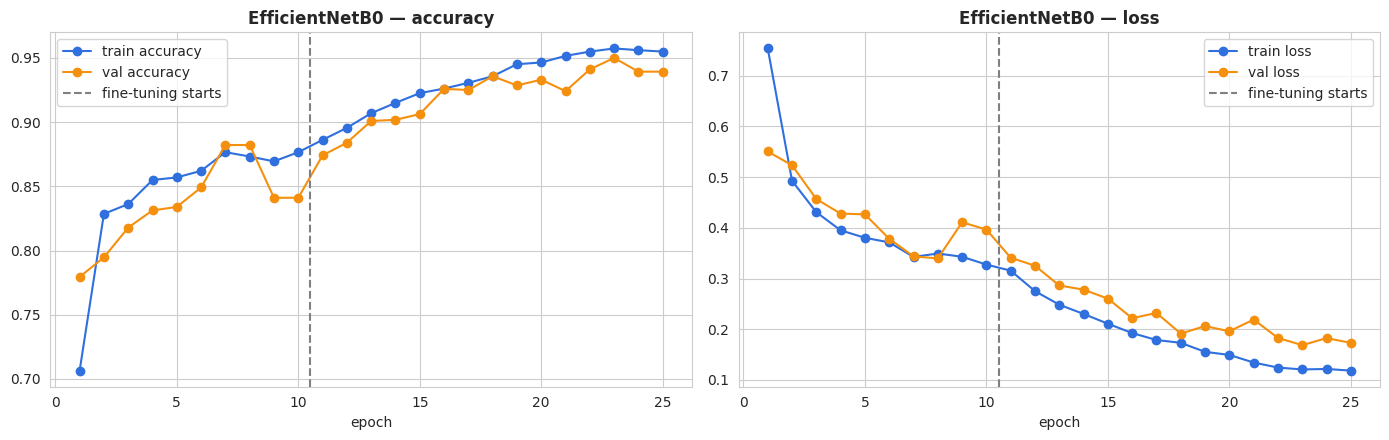

EfficientNetB0 ➜  Validation accuracy: 0.9500


In [22]:
plot_history([history_head, history_ft], "EfficientNetB0", split_at=len(history_head.epoch))

tl_val_loss, tl_val_acc = tl_model.evaluate(val_ds, verbose=0)
print(f"EfficientNetB0 ➜  Validation accuracy: {tl_val_acc:.4f}")

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 Observation</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Watch the jump after the grey dashed line — when fine-tuning starts, validation accuracy usually climbs sharply.
     That's the pretrained model <b>adapting its features</b> from everyday photos to MRI scans.</div>
</div>

<div style="background:#2E9E5B;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 9</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🏆 Compare Models & Final Test Evaluation</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Pick the winner on validation, then judge it ONCE on the unseen test set</p>
</div>

<div style="border:2px solid #D64545;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#D64545;font-family:Georgia;margin:0 0 8px 0;">⚖️ Golden rule</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">We choose the model using <b>validation</b> data. The <b>test</b> set is the final board exam —
     you don't practise on the exam paper! Tuning while looking at test results = data leakage.</div>
</div>

In [23]:
comparison = pd.DataFrame({
    "Model": ["Baseline CNN (scratch)", "EfficientNetB0 (transfer learning)"],
    "Validation Accuracy": [cnn_val_acc, tl_val_acc],
    "Parameters": [baseline_model.count_params(), tl_model.count_params()],
}).sort_values("Validation Accuracy", ascending=False).reset_index(drop=True)

best_model = tl_model if tl_val_acc >= cnn_val_acc else baseline_model
print("🏆 Winner:", best_model.name)
comparison.style.format({"Validation Accuracy": "{:.2%}", "Parameters": "{:,}"})

🏆 Winner: efficientnet_tl


,Model,Validation Accuracy,Parameters
0,EfficientNetB0 (transfer learning),95.00%,"4,054,695"
1,Baseline CNN (scratch),77.86%,"423,268"


In [24]:
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

test_acc = accuracy_score(y_true, y_pred)
print(f"\n🎯 FINAL TEST ACCURACY ({best_model.name}): {test_acc:.2%}\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step

🎯 FINAL TEST ACCURACY (efficientnet_tl): 89.00%

              precision    recall  f1-score   support

      glioma      0.961     0.743     0.838       400
  meningioma      0.851     0.828     0.839       400
     notumor      0.932     0.993     0.961       400
   pituitary      0.838     0.998     0.911       400

    accuracy                          0.890      1600
   macro avg      0.896     0.890     0.887      1600
weighted avg      0.896     0.890     0.887      1600



<div style="border:2px solid #2F6FDE;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2F6FDE;font-family:Georgia;margin:0 0 8px 0;">📊 Reading the report — in medical language</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><b>Precision</b> — when the model says “glioma”, how often is it right? (avoids false alarms)<br>
     <b>Recall</b> (= <b>sensitivity</b> in medicine) — of all real glioma patients, how many did the model catch? (avoids missed patients)<br>
     <b>F1-score</b> — balance of the two · <b>Support</b> — number of test scans in that class<br><br>
     🩺 In medicine, <b>recall for tumor classes is usually more important than precision</b> — a false alarm leads to one more check-up,
     but a missed tumor can cost a life.</div>
</div>

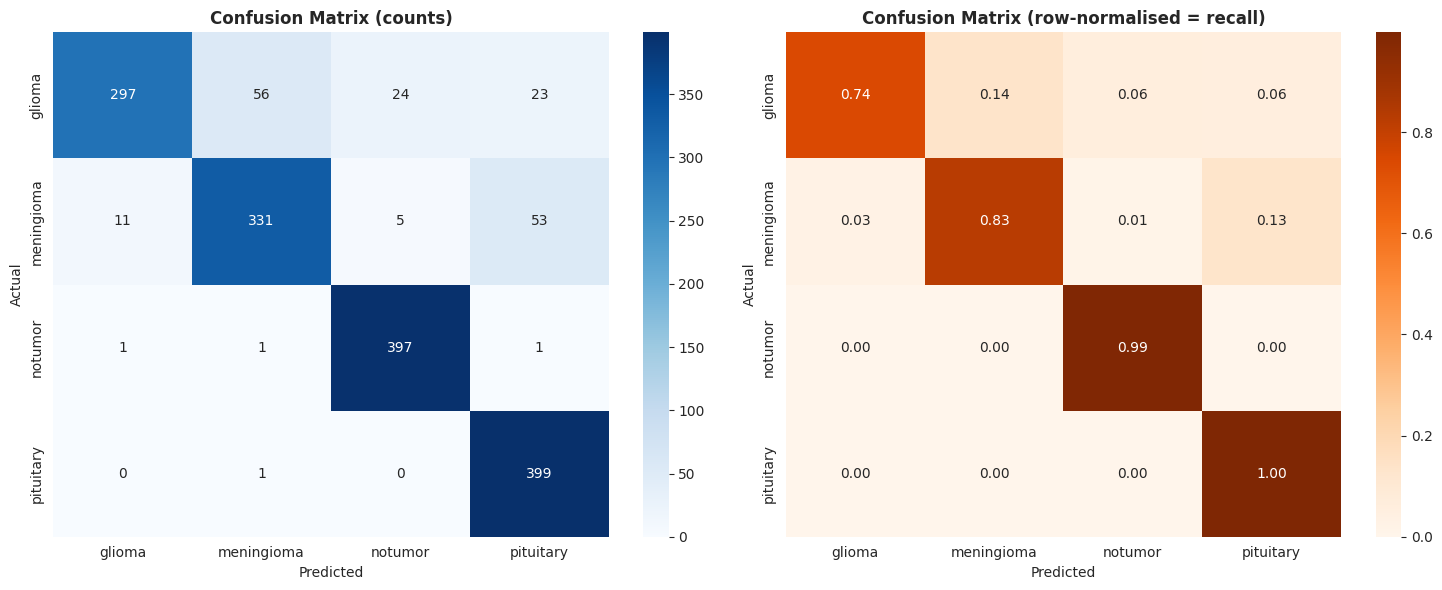

In [25]:
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)", fontweight="bold")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Oranges",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Confusion Matrix (row-normalised = recall)", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 Observation</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">The <b>diagonal</b> = correct predictions. Look for the biggest off-diagonal cells — usually <b>glioma ↔ meningioma</b>.
     Now look at the <b>notumor column</b>: every number there (except the diagonal) is a <b>tumor the model missed</b> ⚠️ — the next step focuses on exactly that.</div>
</div>

<div style="background:#D64545;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 10</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🩺 Medical Evaluation — Tumor vs No Tumor</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">The question a doctor really asks first: does this patient have a tumor at all?</p>
</div>

<div style="border:2px solid #D64545;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#D64545;font-family:Georgia;margin:0 0 8px 0;">🔀 Turning 4 classes into a screening test</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">We group <b>glioma + meningioma + pituitary</b> = <b>“Tumor”</b> and keep <b>notumor</b> = <b>“Healthy”</b>.<br><br>
     <b>Sensitivity</b> = tumors correctly detected ÷ all real tumors ➜ <i>“Did we catch the sick patients?”</i><br>
     <b>Specificity</b> = healthy correctly cleared ÷ all real healthy ➜ <i>“Did we avoid scaring healthy people?”</i><br>
     ❗ <b>False Negative</b> = tumor predicted as healthy = <b>the most dangerous mistake</b>.</div>
</div>

Sensitivity (tumor recall)    : 97.58%
Specificity (healthy recall)  : 99.25%
❗ Missed tumors (False Neg.)  : 29
False alarms (False Pos.)     : 3


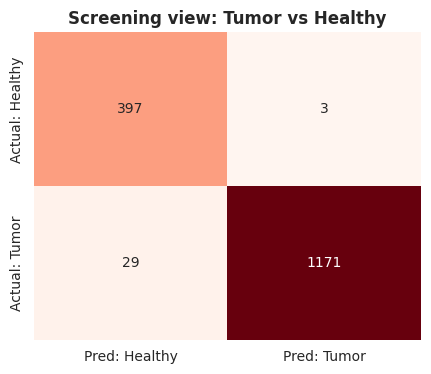

In [26]:
true_tumor = (y_true != NOTUMOR_IDX).astype(int)
pred_tumor = (y_pred != NOTUMOR_IDX).astype(int)

TP = int(((true_tumor == 1) & (pred_tumor == 1)).sum())
FN = int(((true_tumor == 1) & (pred_tumor == 0)).sum())
TN = int(((true_tumor == 0) & (pred_tumor == 0)).sum())
FP = int(((true_tumor == 0) & (pred_tumor == 1)).sum())

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)
print(f"Sensitivity (tumor recall)    : {sensitivity:.2%}")
print(f"Specificity (healthy recall)  : {specificity:.2%}")
print(f"❗ Missed tumors (False Neg.)  : {FN}")
print(f"False alarms (False Pos.)     : {FP}")

plt.figure(figsize=(5, 4))
sns.heatmap([[TN, FP], [FN, TP]], annot=True, fmt="d", cmap="Reds",
            xticklabels=["Pred: Healthy", "Pred: Tumor"], yticklabels=["Actual: Healthy", "Actual: Tumor"], cbar=False)
plt.title("Screening view: Tumor vs Healthy", fontweight="bold"); plt.show()

<div style="border:2px solid #F5900F;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#F5900F;font-family:Georgia;margin:0 0 8px 0;">🎚️ Making the model more careful — adjusting the threshold</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">By default the model picks the class with the highest probability. For screening we can be <b>more cautious</b>:
     call a scan <b>“Healthy” only if P(notumor) is very high</b> (e.g. ≥ 0.80). Otherwise send it to the doctor.<br>
     This trades a few extra false alarms for <b>fewer missed tumors</b> — a trade-off hospitals usually prefer.</div>
</div>

In [27]:
rows = []
for thr in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]:
    pred_t = (y_prob[:, NOTUMOR_IDX] < thr).astype(int)          # tumor unless very sure it's healthy
    fn = int(((true_tumor == 1) & (pred_t == 0)).sum())
    fp = int(((true_tumor == 0) & (pred_t == 1)).sum())
    rows.append({"healthy_threshold": thr,
                 "sensitivity": ((true_tumor == 1) & (pred_t == 1)).sum() / true_tumor.sum(),
                 "specificity": ((true_tumor == 0) & (pred_t == 0)).sum() / (1 - true_tumor).sum(),
                 "missed_tumors (FN)": fn, "false_alarms (FP)": fp})

pd.DataFrame(rows).style.format({"sensitivity": "{:.2%}", "specificity": "{:.2%}"})

,healthy_threshold,sensitivity,specificity,missed_tumors (FN),false_alarms (FP)
0,0.500000,97.75%,99.25%,27,3
1,0.600000,98.00%,98.25%,24,7
2,0.700000,98.42%,97.75%,19,9
3,0.800000,98.67%,97.25%,16,11
4,0.900000,98.92%,95.75%,13,17
5,0.950000,99.33%,95.25%,8,19


<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 How to choose?</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">As the threshold goes up, <b>missed tumors go down</b> and <b>false alarms go up</b>. There's no single “correct” value —
     it's a <b>business/medical decision</b> made together with doctors. Pick the threshold where missed tumors are
     near zero while false alarms stay manageable.</div>
</div>

<div style="background:#D64545;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 11</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🕵️ Error Analysis</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Look at the mistakes — they teach more than the successes</p>
</div>

Misclassified: 176 of 1600 test scans


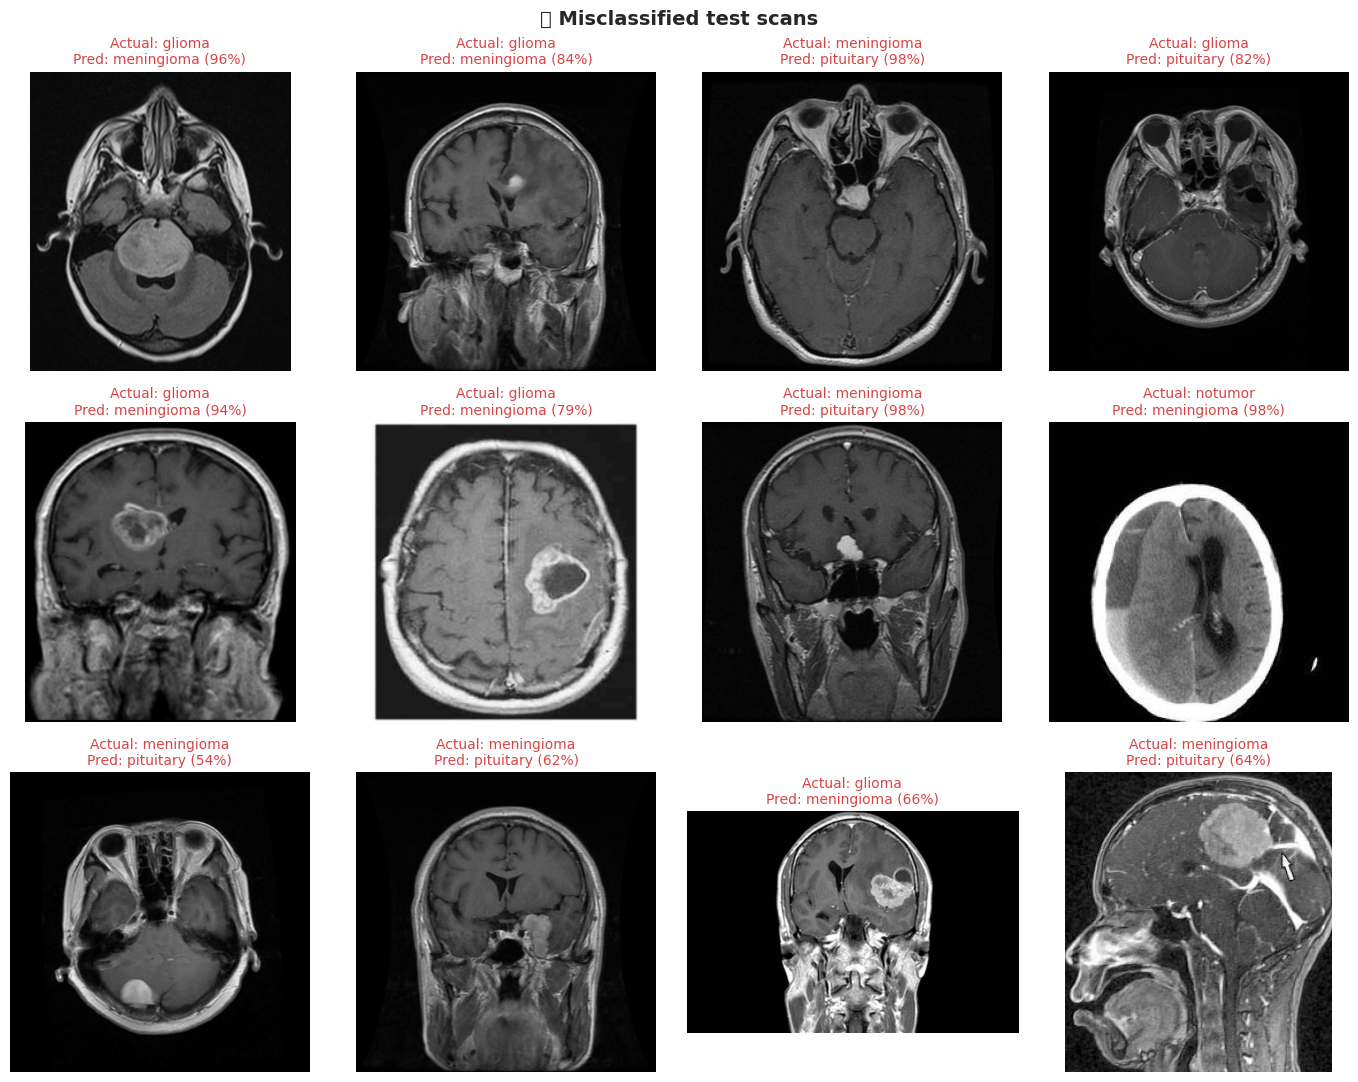

In [28]:
wrong_idx = np.where(y_pred != y_true)[0]
print(f"Misclassified: {len(wrong_idx)} of {len(y_true)} test scans")

if len(wrong_idx):
    show = np.random.choice(wrong_idx, size=min(12, len(wrong_idx)), replace=False)
    plt.figure(figsize=(14, 11))
    for i, idx in enumerate(show):
        plt.subplot(3, 4, i + 1)
        plt.imshow(Image.open(TEST_PATHS[idx]).convert("RGB"))
        plt.title(f"Actual: {CLASS_NAMES[y_true[idx]]}\nPred: {CLASS_NAMES[y_pred[idx]]} ({y_prob[idx].max():.0%})",
                  color="#D64545", fontsize=10)
        plt.axis("off")
    plt.suptitle("❌ Misclassified test scans", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

In [29]:
# Which confusions happen most often?
pairs = Counter((CLASS_NAMES[t], CLASS_NAMES[p]) for t, p in zip(y_true[wrong_idx], y_pred[wrong_idx]))
pd.DataFrame(pairs.most_common(8), columns=["(Actual, Predicted)", "Count"])

,"(Actual, Predicted)",Count
0,"(glioma, meningioma)",56
1,"(meningioma, pituitary)",53
2,"(glioma, notumor)",24
3,"(glioma, pituitary)",23
4,"(meningioma, glioma)",11
5,"(meningioma, notumor)",5
6,"(notumor, glioma)",1
7,"(notumor, meningioma)",1


<div style="border:2px solid #F5900F;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#F5900F;font-family:Georgia;margin:0 0 8px 0;">🤔 Questions to discuss in class</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><ul style="margin:0;"><li>Are mistakes mostly from one <b>view</b> (top / side / front)?</li>
     <li>Are the wrong predictions <b>confident</b> (90%+) or <b>unsure</b> (40–60%)? Unsure ones could be sent to a doctor automatically.</li>
     <li>Are some tumors very <b>small</b> or low-contrast — hard even for humans?</li></ul></div>
</div>

<div style="background:#F5900F;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 12</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🔥 Explainability with Grad-CAM</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Is the model looking at the tumor — or at something irrelevant?</p>
</div>

<div style="border:2px solid #F5900F;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#F5900F;font-family:Georgia;margin:0 0 8px 0;">🔦 Why explainability is critical in medicine</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><b>Grad-CAM</b> draws a <b>heatmap</b> of the regions that most influenced the prediction.<br>
     A doctor will only trust the AI if it “points” at the tumor 👉 — not at the skull, text labels or the black background.<br><br>
     ✅ Heatmap on the tumor ➜ the model learned the right thing.<br>
     ⚠️ Heatmap on corners / scanner text ➜ the model found a <b>shortcut</b> (a hidden bias in the dataset).</div>
</div>

In [ ]:
# Grad-CAM for the EfficientNet model (uses the last convolutional layer of the base)
last_conv_layer = base_model.get_layer("top_activation")
conv_feature_model = keras.Model(base_model.inputs, [last_conv_layer.output, base_model.output])
gap_layer, dense_layer = tl_model.get_layer("gap"), tl_model.get_layer("predictions")

def make_gradcam_heatmap(img_array):
    """img_array: (1, H, W, 3) raw 0-255 image. Returns heatmap (h, w) and predicted class index."""
    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, base_out = conv_feature_model(img_tensor, training=False)
        preds = dense_layer(gap_layer(base_out))
        pred_index = int(tf.argmax(preds[0]))
        class_score = preds[:, pred_index]
    grads = tape.gradient(class_score, conv_out)               # how much each feature map matters
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))            # one importance weight per channel
    heatmap = tf.reduce_sum(conv_out[0] * weights, axis=-1)    # weighted sum of feature maps
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), pred_index

def gradcam_for(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE, color_mode="rgb")
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)
    heatmap, idx = make_gradcam_heatmap(arr)
    heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE).numpy()[..., 0]
    return np.array(img), heatmap, CLASS_NAMES[idx]

# 6 random tumor scans from the test set
tumor_paths = [p for p in TEST_PATHS if os.path.basename(os.path.dirname(p)) != "notumor"]
sample_paths = random.sample(tumor_paths, 6)
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, p in enumerate(sample_paths):
    img, heat, pred = gradcam_for(p)
    axes[0, i].imshow(img); axes[0, i].set_title(f"Actual: {os.path.basename(os.path.dirname(p))}"); axes[0, i].axis("off")
    axes[1, i].imshow(img); axes[1, i].imshow(heat, cmap="jet", alpha=0.45)
    axes[1, i].set_title(f"Pred: {pred}"); axes[1, i].axis("off")
plt.suptitle("🔥 Grad-CAM — where the model looks", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">📝 Observation</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">In most tumor scans the heatmap should glow around the <b>bright mass</b>. For <b>pituitary</b> cases it usually focuses on the
     <b>centre-bottom</b> of the brain — exactly where the pituitary gland is. That's a good sign the model learned real anatomy 🧠</div>
</div>

<div style="background:#0E9F8E;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 13</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">💾 Save the Model & Predict on New Scans</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">Turn the trained model into something a hospital app could use</p>
</div>

In [ ]:
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "brain_tumor_classifier.keras")
best_model.save(FINAL_MODEL_PATH)
with open(os.path.join(OUTPUT_DIR, "class_names.json"), "w") as f:
    json.dump(CLASS_NAMES, f)
print("✅ Saved:", FINAL_MODEL_PATH)

# Prove it works: reload from disk and check test accuracy
reloaded = keras.models.load_model(FINAL_MODEL_PATH)
_, reloaded_acc = reloaded.evaluate(test_ds, verbose=0)
print(f"Reloaded model test accuracy: {reloaded_acc:.2%}")

<div style="border:2px solid #0E9F8E;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#0E9F8E;font-family:Georgia;margin:0 0 8px 0;">📥 Downloading your model</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Files saved in <code>/kaggle/working</code> appear in the right panel under <b>Output</b>. After
     <b>Save Version ➜ Save &amp; Run All</b>, they're kept permanently and can be downloaded or used in a Streamlit/Flask app.</div>
</div>

In [ ]:
HEALTHY_THRESHOLD = 0.80   # call a scan "healthy" only if the model is at least this sure (see Step 10)

def predict_scan(path, model=reloaded):
    """Predict one MRI scan and return a triage-style result."""
    img = keras.utils.load_img(path, target_size=IMG_SIZE, color_mode="rgb")
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)   # raw 0-255, preprocessing is inside the model
    probs = model.predict(arr, verbose=0)[0]
    label = CLASS_NAMES[int(probs.argmax())]
    if probs[NOTUMOR_IDX] >= HEALTHY_THRESHOLD:
        triage = "🟢 Likely healthy"
    elif label == "notumor":
        triage = "🟡 Uncertain — doctor review"
    else:
        triage = f"🔴 Possible {label} — priority review"
    return img, probs, triage

demo_paths = random.sample(TEST_PATHS, 8)
plt.figure(figsize=(16, 10))
for i, p in enumerate(demo_paths):
    img, probs, triage = predict_scan(p)
    top = probs.argsort()[::-1][:2]
    plt.subplot(2, 4, i + 1); plt.imshow(img); plt.axis("off")
    plt.title(f"Actual: {os.path.basename(os.path.dirname(p))}\n"
              + "\n".join(f"{CLASS_NAMES[k]}: {probs[k]:.0%}" for k in top)
              + f"\n{triage}", fontsize=9.5)
plt.suptitle("🆕 Triage predictions on test scans", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

<div style="border:2px solid #2F6FDE;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2F6FDE;font-family:Georgia;margin:0 0 8px 0;">🖼️ Try your own scan</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;">Upload any MRI image via <b>+ Add Input ➜ Upload</b> (or find one on the web), then run:<br>
     <code>img, probs, triage = predict_scan("/kaggle/input/&lt;your-folder&gt;/&lt;your-image&gt;.jpg"); print(triage)</code></div>
</div>

In [ ]:
# Full prediction report for the test set — the deliverable for the hospital
report = pd.DataFrame({
    "image": [os.path.basename(p) for p in TEST_PATHS],
    "actual": [CLASS_NAMES[i] for i in y_true],
    "predicted": [CLASS_NAMES[i] for i in y_pred],
    "confidence": y_prob.max(axis=1).round(4),
    "p_notumor": y_prob[:, NOTUMOR_IDX].round(4),
})
report["correct"] = report["actual"] == report["predicted"]
report["needs_review"] = (report["p_notumor"] < HEALTHY_THRESHOLD) | (report["confidence"] < 0.60)
report.to_csv(os.path.join(OUTPUT_DIR, "test_predictions_report.csv"), index=False)

print(f"✅ Saved report for {len(report)} scans")
print(f"Scans flagged for doctor review: {report['needs_review'].sum()} ({report['needs_review'].mean():.1%})")
report.head(10)

<div style="background:#0C244A;padding:18px 22px;border-radius:12px;border-left:10px solid #F5900F;">
  <span style="color:#F5900F;font-family:Arial;font-size:14px;font-weight:bold;letter-spacing:2px;">STEP 14</span>
  <h2 style="color:white;font-family:Georgia;margin:6px 0 4px 0;">🏁 Conclusion & Summary</h2>
  <p style="color:#DCE6F5;font-family:Arial;font-size:15px;margin:0;">What we built, what we learned, and where to go next</p>
</div>

<div style="background:#F7F9FC;border-radius:10px;padding:16px 22px;font-family:Arial;font-size:15px;line-height:1.8;">
<h3 style="font-family:Georgia;color:#0C244A;margin-top:0;">✅ Project Summary</h3>
<table style="font-size:14.5px;">
<tr><th style="text-align:left;">Stage</th><th style="text-align:left;">What we did</th></tr>
<tr><td>📂 Data</td><td>Loaded ~7,000 real MRI files of mixed sizes &amp; colour modes from folders</td></tr>
<tr><td>🔍 EDA</td><td>Class balance, sample scans, size/mode check, <b>duplicate &amp; leakage check</b></td></tr>
<tr><td>🔄 Augmentation</td><td>MRI-safe: horizontal flip, small rotation, zoom, contrast</td></tr>
<tr><td>🏗️ Model 1</td><td>4-block CNN from scratch with class weights — baseline</td></tr>
<tr><td>🚀 Model 2</td><td>EfficientNetB0 transfer learning + fine-tuning — best model</td></tr>
<tr><td>🏆 Evaluation</td><td>Test accuracy, classification report, confusion matrices</td></tr>
<tr><td>🩺 Medical view</td><td>Tumor vs Healthy: sensitivity, specificity, missed tumors, threshold tuning</td></tr>
<tr><td>🔥 Explainability</td><td>Grad-CAM heatmaps — checking the model looks at the tumor</td></tr>
<tr><td>💾 Deployment-ready</td><td>Saved <code>.keras</code> model, triage function, CSV report with review flags</td></tr>
</table>
</div>

<div style="border:2px solid #2E9E5B;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#2E9E5B;font-family:Georgia;margin:0 0 8px 0;">🧠 Key Takeaways</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><ol style="margin:0;">
     <li><b>Transfer learning + fine-tuning</b> beats training from scratch on small medical datasets.</li>
     <li><b>Accuracy is not enough in healthcare</b> — sensitivity and missed tumors matter more.</li>
     <li><b>Thresholds are business decisions</b> — trade false alarms for fewer missed patients.</li>
     <li><b>Always check for duplicates/leakage</b> — merged medical datasets often contain them.</li>
     <li><b>Explainability builds trust</b> — doctors need to see <i>why</i> the model decided.</li>
     </ol></div>
</div>

<div style="border:2px solid #6C3FC5;border-radius:10px;padding:14px 18px;background:#FAFCFF;">
  <h4 style="color:#6C3FC5;font-family:Georgia;margin:0 0 8px 0;">📝 Student Tasks (submit as your capstone)</h4>
  <div style="font-family:Arial;font-size:14.5px;color:#222;line-height:1.6;"><ol style="margin:0;">
     <li><b>Remove leaked images</b> (found in Step 4) from the test set and re-measure accuracy. How much did it change?</li>
     <li>Replace EfficientNetB0 with <b>ResNet50</b> or <b>DenseNet121</b> (remember their own <code>preprocess_input</code>!). Compare accuracy &amp; training time.</li>
     <li>Train <b>without</b> data augmentation. Does overfitting increase? Show the curves.</li>
     <li>Build a <b>binary model</b> (Tumor vs No Tumor) directly and compare its sensitivity with Step 10.</li>
     <li>Run Grad-CAM on 5 <b>misclassified</b> scans. Explain in 2–3 lines what confused the model.</li>
     <li>Write a one-page <b>report for a hospital</b>: accuracy, sensitivity, chosen threshold, limitations and ethics.</li>
     <li>⭐ Bonus: Build a <b>Streamlit</b> app — upload a scan, show the prediction, triage colour and Grad-CAM heatmap.</li>
     </ol></div>
</div>

<div style="background:#0C244A;padding:16px;border-radius:12px;text-align:center;font-family:Arial;">
  <p style="color:white;font-size:16px;margin:0;">🎉 Congratulations on completing the Brain Tumor MRI capstone! 🎉</p>
  <p style="color:#F5900F;font-size:14px;margin:6px 0 0 0;">Kumod Sharma · Data Science Consultant · Data Analytics &amp; Generative AI</p>
</div>